In [2]:
import os

import cv2
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from skimage import exposure
from skimage import feature
from imutils import paths
import imutils
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

#Partie III : Sélection de caractéristiques avec PCA

# Sélection de caractéristiques avec PCA appliqué sur les caractéristiques LBP

In [4]:
# Fonction pour calculer l'histogramme des caractéristiques LBP (Local Binary Pattern)
def compute_lbp(image, eps=1e-7, numPoints=24, radius=8):
    lbp = feature.local_binary_pattern(image, numPoints, radius, method="uniform")
    (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, numPoints + 3), range=(0, numPoints + 2))
    hist = hist.astype("float")
    hist /= (hist.sum() + eps)
    return hist

In [6]:
import  os
# Sélection de caractéristiques avec PCA appliqué sur les caractéristiques LBP (train_data_lbp,test_data_lbp ,train_labels & test_labels
train_data_lbp = []
train_labels = []
test_data_lbp = []
test_labels = []

for imagePath in paths.list_images('caltech_dataset/train_set'):
    print(imagePath)
    # TODO : Extraire la classe de chaque image à partir de son chemin
    label = imagePath.split(os.path.sep)[-2]

    image = cv2.imread(imagePath)

    #TODO: Convertir l'image en niveaux de gris
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    hist = compute_lbp(gray_image)
    # TODO : Ajouter le vecteur de caractéristiques hist à la liste des données d'apprentissage
    train_data_lbp.append(hist)
    train_labels.append(label)


for imagePath in paths.list_images('caltech_dataset/test_set'):
    print(imagePath)
     # TODO : Extraire la classe de chaque image à partir de son chemin
    label = imagePath.split(os.path.sep)[-2]

    image = cv2.imread(imagePath)

    #TODO: Convertir l'image en niveaux de gris
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    hist = compute_lbp(gray_image)
    # TODO : Ajouter le vecteur de caractéristiques hist à la liste des données de test
    test_data_lbp.append(hist)
    test_labels.append(label)

caltech_dataset/train_set\car\01.png
caltech_dataset/train_set\car\02.png
caltech_dataset/train_set\car\03.png
caltech_dataset/train_set\car\04.png
caltech_dataset/train_set\car\05.png
caltech_dataset/train_set\car\06.png
caltech_dataset/train_set\car\07.png
caltech_dataset/train_set\car\08.png
caltech_dataset/train_set\car\09.png
caltech_dataset/train_set\car\10.png
caltech_dataset/train_set\car\11.png
caltech_dataset/train_set\car\12.png
caltech_dataset/train_set\car\13.png
caltech_dataset/train_set\car\14.png
caltech_dataset/train_set\car\15.png
caltech_dataset/train_set\car\16.png
caltech_dataset/train_set\car\17.png
caltech_dataset/train_set\car\18.png
caltech_dataset/train_set\car\19.png
caltech_dataset/train_set\car\20.png
caltech_dataset/train_set\motorbike\01.png
caltech_dataset/train_set\motorbike\02.png
caltech_dataset/train_set\motorbike\03.png
caltech_dataset/train_set\motorbike\04.png
caltech_dataset/train_set\motorbike\05.png
caltech_dataset/train_set\motorbike\06.png
ca

#Application de PCA pour la réduction de dimension

In [7]:
# Application de PCA pour la réduction de dimension
pca = PCA(n_components=20, whiten=True)
train_data_lbp_pca = pca.fit_transform(train_data_lbp)
test_data_lbp_pca = pca.transform(test_data_lbp)


# Entraînement et évaluation des modèles après réduction de dimension


In [9]:
# TODO : Initialiser les modèles de classification KNN (model1) et SVM (model 2)
knn = KNeighborsClassifier(n_neighbors=7)
svm = SVC(kernel='linear', C=1.0, gamma='auto')


In [10]:
# TODO : Entraîner le modèle KNN avec les données train
knn.fit(train_data_lbp_pca, train_labels)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[<U9](3,)","['car','motorbike','person']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [13]:
# TODO :  prédire les étiquettes pour les images de test en utilsant le model KNN
from sklearn.metrics import accuracy_score
prediction_knn = knn.predict(test_data_lbp_pca)
print(accuracy_score(prediction_knn, test_labels))

0.6666666666666666


[INFO] Évaluation du modèle KNN
Matrice de confusion pour KNN :
[[3 1 1]
 [0 3 0]
 [2 1 4]]
              precision    recall  f1-score   support

         car       0.60      0.60      0.60         5
   motorbike       0.60      1.00      0.75         3
      person       0.80      0.57      0.67         7

    accuracy                           0.67        15
   macro avg       0.67      0.72      0.67        15
weighted avg       0.69      0.67      0.66        15



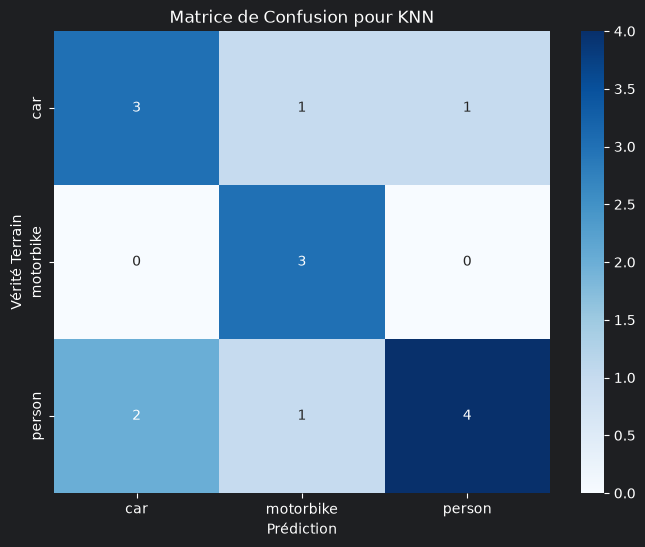

In [16]:
# TODO : Évaluer la précision du modèle SVM avec la Matrice de confusion et le rapport de classification pour le modèle KNN
from sklearn.metrics import confusion_matrix , classification_report
print('[INFO] Évaluation du modèle KNN')
print('Matrice de confusion pour KNN :')
conf_matrix_knn = confusion_matrix(prediction_knn, test_labels)
print(conf_matrix_knn)
print(classification_report(prediction_knn, test_labels))

# Visualisation de la matrice de confusion pour KNN
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_knn, annot=True, fmt="d", cmap="Blues", xticklabels=np.unique(test_labels), yticklabels=np.unique(test_labels))
plt.title("Matrice de Confusion pour KNN")
plt.xlabel("Prédiction")
plt.ylabel("Vérité Terrain")
plt.show()

In [17]:
# TODO : Entraîner le modèle svm avec les données train
svm.fit(train_data_lbp_pca, train_labels)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'auto'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [22]:
# TODO :  prédire les étiquettes pour les images de test en utilsant le model SVM
from sklearn.metrics import precision_score
prediction_svm = svm.predict(test_data_lbp_pca)
print('Précision du modèle SVM avec PCA sur LBP :\n', classification_report(prediction_svm, test_labels))

Précision du modèle SVM avec PCA sur LBP :
               precision    recall  f1-score   support

         car       0.80      1.00      0.89         4
   motorbike       0.60      0.60      0.60         5
      person       0.80      0.67      0.73         6

    accuracy                           0.73        15
   macro avg       0.73      0.76      0.74        15
weighted avg       0.73      0.73      0.73        15



[INFO] Évaluation du modèle SVM
Matrice de confusion pour SVM :
[[4 0 0]
 [1 3 1]
 [0 2 4]]
              precision    recall  f1-score   support

         car       0.80      1.00      0.89         4
   motorbike       0.60      0.60      0.60         5
      person       0.80      0.67      0.73         6

    accuracy                           0.73        15
   macro avg       0.73      0.76      0.74        15
weighted avg       0.73      0.73      0.73        15



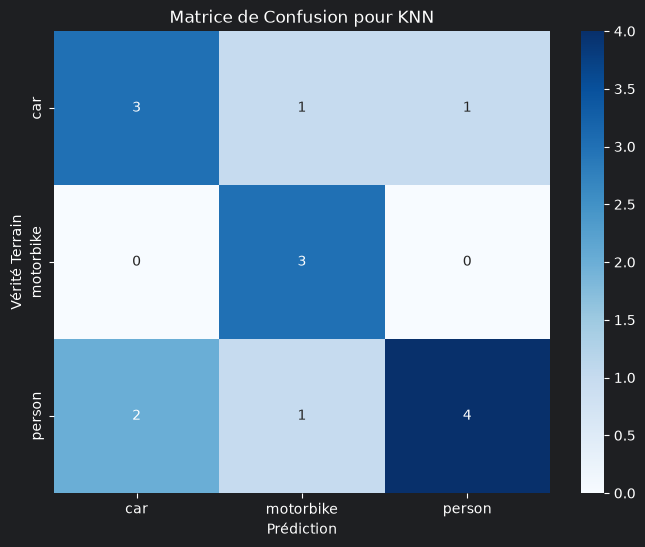

In [23]:
# TODO : Évaluer la précision du modèle SVM avec la Matrice de confusion et le rapport de classification
from sklearn.metrics import confusion_matrix , classification_report
print('[INFO] Évaluation du modèle SVM')
print('Matrice de confusion pour SVM :')
conf_matrix_svm = confusion_matrix(prediction_svm, test_labels)
print(conf_matrix_svm)
print(classification_report(prediction_svm, test_labels))

# Visualisation de la matrice de confusion pour KNN
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_knn, annot=True, fmt="d", cmap="Blues", xticklabels=np.unique(test_labels), yticklabels=np.unique(test_labels))
plt.title("Matrice de Confusion pour KNN")
plt.xlabel("Prédiction")
plt.ylabel("Vérité Terrain")
plt.show()